# Loading Data

In [62]:
# Importing libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import matplotlib.dates as mdates
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import itertools

In [7]:
# # Code to concatenate individual 2016-2026 data into one csv file
# import glob
# import os

# df = pd.concat(map(pd.read_csv, glob.glob(os.path.join('T_T100D_MARKET_US_CARRIER_ONLY_DATA', '*.csv'))), ignore_index=True)
# df.to_csv('T_T100D_MARKET_US_CARRIER_ONLY_DATA/T_T100D_MARKET_US_CARRIER_ONLY_2016-2026.csv', index=False)

In [8]:
# Read concatenated 2016-2026 data
df = pd.read_csv('../data/T_T100D_MARKET_US_CARRIER_ONLY_DATA/T_T100D_MARKET_US_CARRIER_ONLY_2016-2026.csv')
df.head()

,PASSENGERS,FREIGHT,MAIL,DISTANCE,UNIQUE_CARRIER,UNIQUE_CARRIER_NAME,ORIGIN_AIRPORT_ID,ORIGIN,ORIGIN_CITY_NAME,ORIGIN_STATE_ABR,DEST_AIRPORT_ID,DEST,DEST_CITY_NAME,DEST_STATE_ABR,YEAR,QUARTER,MONTH,DISTANCE_GROUP
0,0.0,0.0,0.0,0.0,09Q,"Swift Air, LLC d/b/a Eastern Air Lines d/b/a E...",11995,GSO,"Greensboro/High Point, NC",NC,11995,GSO,"Greensboro/High Point, NC",NC,2016,2,5,1
1,0.0,0.0,0.0,0.0,09Q,"Swift Air, LLC d/b/a Eastern Air Lines d/b/a E...",11995,GSO,"Greensboro/High Point, NC",NC,11995,GSO,"Greensboro/High Point, NC",NC,2016,3,8,1
2,0.0,0.0,0.0,0.0,09Q,"Swift Air, LLC d/b/a Eastern Air Lines d/b/a E...",13303,MIA,"Miami, FL",FL,13303,MIA,"Miami, FL",FL,2016,1,2,1
3,0.0,0.0,0.0,0.0,09Q,"Swift Air, LLC d/b/a Eastern Air Lines d/b/a E...",13303,MIA,"Miami, FL",FL,13303,MIA,"Miami, FL",FL,2016,4,11,1
4,0.0,0.0,0.0,0.0,1BQ,"Eastern Airlines f/k/a Dynamic Airways, LLC",12478,JFK,"New York, NY",NY,12478,JFK,"New York, NY",NY,2016,2,6,1


In [9]:
# Check dimensions of data
df.shape

(2592215, 18)

# Data Cleaning

### 1. Missing values

In [10]:
# Checking missing values per column
df.isnull().sum()

PASSENGERS               0
FREIGHT                205
MAIL                     0
DISTANCE                 0
UNIQUE_CARRIER          37
UNIQUE_CARRIER_NAME     37
ORIGIN_AIRPORT_ID        0
ORIGIN                   0
ORIGIN_CITY_NAME         0
ORIGIN_STATE_ABR         0
DEST_AIRPORT_ID          0
DEST                     0
DEST_CITY_NAME           0
DEST_STATE_ABR           0
YEAR                     0
QUARTER                  0
MONTH                    0
DISTANCE_GROUP           0
dtype: int64

In [11]:
# Number and percentage of rows with null data
print(f'Number of missing rows:{df.isnull().any(axis=1).sum()}')
print(f'Percentage of missing rows:{df.isnull().any(axis=1).sum() / len(df) * 100}')

Number of missing rows:242
Percentage of missing rows:0.009335645384352763


In [12]:
# The percentage can also be calculated using .mean()
df.isna().any(axis=1).mean() * 100

0.009335645384352763

* Because the percentage of rows with missing values is very small (less than 5%, specifically ~.009%), I will drop these rows and not perform data imputation, which could potentially distort the data.

In [13]:
# Save data with missing values into its own DataFrame and drop from original DataFrame
df_null = df[df.isnull().any(axis=1)]

df_cleaned = df.dropna().reset_index(drop=True)

In [14]:
# Confirm that null and valid counts equals total count of original dataset
print(len(df_null) + len(df_cleaned))
print(len(df))

2592215
2592215


### 2. Duplicated Values

In [15]:
# Checking if there are duplicated values
df[df.duplicated()].head()

,PASSENGERS,FREIGHT,MAIL,DISTANCE,UNIQUE_CARRIER,UNIQUE_CARRIER_NAME,ORIGIN_AIRPORT_ID,ORIGIN,ORIGIN_CITY_NAME,ORIGIN_STATE_ABR,DEST_AIRPORT_ID,DEST,DEST_CITY_NAME,DEST_STATE_ABR,YEAR,QUARTER,MONTH,DISTANCE_GROUP
195,0.0,0.0,0.0,10.0,G4,Allegiant Air,15304,TPA,"Tampa, FL",FL,14112,PIE,"St. Petersburg, FL",FL,2016,4,12,1
396,0.0,0.0,0.0,24.0,UA,United Air Lines Inc.,12191,HOU,"Houston, TX",TX,12266,IAH,"Houston, TX",TX,2016,2,5,1
398,0.0,0.0,0.0,24.0,UA,United Air Lines Inc.,12191,HOU,"Houston, TX",TX,12266,IAH,"Houston, TX",TX,2016,3,8,1
557,0.0,0.0,0.0,37.0,V8,Iliamna Air Taxi,12321,ILI,"Iliamna, AK",AK,14268,PTA,"Port Alsworth, AK",AK,2016,1,3,1
659,0.0,0.0,0.0,45.0,UA,United Air Lines Inc.,10821,BWI,"Baltimore, MD",MD,12264,IAD,"Washington, DC",VA,2016,2,6,1


In [16]:
# Checking number of identical rows for each year
for year in df['YEAR'].unique():
    df_year = df.loc[df['YEAR']==year]
    print(f'Number of duplicated rows for year {year}: {len(df_year.loc[df_year.duplicated()])}')

Number of duplicated rows for year 2016: 122
Number of duplicated rows for year 2017: 92
Number of duplicated rows for year 2018: 123
Number of duplicated rows for year 2019: 182
Number of duplicated rows for year 2020: 116
Number of duplicated rows for year 2021: 42
Number of duplicated rows for year 2022: 123
Number of duplicated rows for year 2023: 99
Number of duplicated rows for year 2024: 141
Number of duplicated rows for year 2025: 229
Number of duplicated rows for year 2026: 199


In [18]:
# Loading separate 2025 data with all fields and checking number of rows to be equal to 2025 portion of complete period dataset
df_test = pd.read_csv('../data/T_T100D_MARKET_US_CARRIER_ONLY_DATA/T_T100D_MARKET_US_CARRIER_ONLY_2025_ALL_FIELDS.csv')
print(f'Length of 2025 dataset with all fields: {len(df_test)}')
print(f"Length of 2025 portion of complete period dataset: {len(df.loc[df['YEAR']==2025])}")

Length of 2025 dataset with all fields: 252665
Length of 2025 portion of complete period dataset: 252665


In [19]:
# Checking dimensions (all 36 fields instead of subset of 18)
df_test.shape

(252665, 36)

In [20]:
# Checking if there are duplicated values using all fields in 2025
df_test[df_test.duplicated()]

,PASSENGERS,FREIGHT,MAIL,DISTANCE,UNIQUE_CARRIER,AIRLINE_ID,UNIQUE_CARRIER_NAME,UNIQUE_CARRIER_ENTITY,REGION,CARRIER,...,DEST_CITY_NAME,DEST_STATE_ABR,DEST_STATE_FIPS,DEST_STATE_NM,DEST_WAC,YEAR,QUARTER,MONTH,DISTANCE_GROUP,CLASS


* By performing the .duplicated() function on the complete 2025 dataset, we can confirm that there are no duplicated values in the 2025 data. All of the supposably duplicated rows in the 2016-2026 dataset, which were identified using the same function, are because I selected only 18 of the 36 fields, so the differences are not captured with the reduced data.
    
* Although I did not download all of the fields from the rest of the years, 2025 was the year with the most suspected duplicate rows. I will trust the cleanliness of the DOT data regarding duplicates.

### 3. Incorrect Data Types

In [21]:
# Checking data types of columns
df_cleaned.dtypes

PASSENGERS             float64
FREIGHT                float64
MAIL                   float64
DISTANCE               float64
UNIQUE_CARRIER          object
UNIQUE_CARRIER_NAME     object
ORIGIN_AIRPORT_ID        int64
ORIGIN                  object
ORIGIN_CITY_NAME        object
ORIGIN_STATE_ABR        object
DEST_AIRPORT_ID          int64
DEST                    object
DEST_CITY_NAME          object
DEST_STATE_ABR          object
YEAR                     int64
QUARTER                  int64
MONTH                    int64
DISTANCE_GROUP           int64
dtype: object

In [22]:
# Detecting mixed data types
for column in df_cleaned.columns:
    print(column,':',pd.api.types.infer_dtype(df_cleaned[column]))

PASSENGERS : floating
FREIGHT : floating
MAIL : floating
DISTANCE : floating
UNIQUE_CARRIER : string
UNIQUE_CARRIER_NAME : string
ORIGIN_AIRPORT_ID : integer
ORIGIN : string
ORIGIN_CITY_NAME : string
ORIGIN_STATE_ABR : string
DEST_AIRPORT_ID : integer
DEST : string
DEST_CITY_NAME : string
DEST_STATE_ABR : string
YEAR : integer
QUARTER : integer
MONTH : integer
DISTANCE_GROUP : integer


* No mixed data types are present.

### 4. Outliers

(a) Numerical Fields

In [23]:
# Viewing only numeric fields
df_cleaned.select_dtypes('number')

,PASSENGERS,FREIGHT,MAIL,DISTANCE,ORIGIN_AIRPORT_ID,DEST_AIRPORT_ID,YEAR,QUARTER,MONTH,DISTANCE_GROUP
0,0.0,0.0,0.0,0.0,11995,11995,2016,2,5,1
1,0.0,0.0,0.0,0.0,11995,11995,2016,3,8,1
2,0.0,0.0,0.0,0.0,13303,13303,2016,1,2,1
3,0.0,0.0,0.0,0.0,13303,13303,2016,4,11,1
4,0.0,0.0,0.0,0.0,12478,12478,2016,2,6,1
...,...,...,...,...,...,...,...,...,...,...
2591968,85988.0,61508.0,0.0,404.0,13204,10397,2026,2,4,1
2591969,86442.0,62436.0,0.0,404.0,13204,10397,2026,1,3,1
2591970,86791.0,153746.0,0.0,404.0,10397,13204,2026,1,3,1
2591971,89674.0,53500.0,0.0,404.0,13204,10397,2026,2,5,1


<AxesSubplot:>

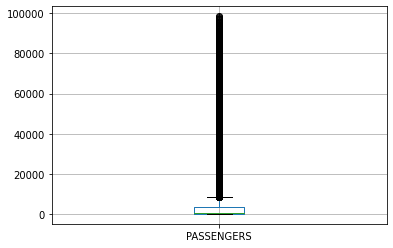

In [24]:
# Boxplot for 'PASSENGERS'
df_cleaned.boxplot(column=['PASSENGERS'])

<AxesSubplot:>

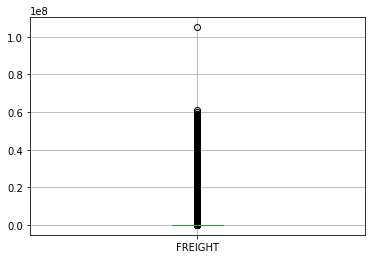

In [25]:
# Boxplot for 'FREIGHT'
df_cleaned.boxplot(column=['FREIGHT'])

In [26]:
# Checking value of top outlier
df_cleaned.FREIGHT.max()

105077869.0

In [27]:
# Checking row with max 'FREIGHT' value
df_cleaned.loc[df_cleaned['FREIGHT']==105077869]

,PASSENGERS,FREIGHT,MAIL,DISTANCE,UNIQUE_CARRIER,UNIQUE_CARRIER_NAME,ORIGIN_AIRPORT_ID,ORIGIN,ORIGIN_CITY_NAME,ORIGIN_STATE_ABR,DEST_AIRPORT_ID,DEST,DEST_CITY_NAME,DEST_STATE_ABR,YEAR,QUARTER,MONTH,DISTANCE_GROUP
791280,0.0,105077869.0,5849.0,0.0,FX,Federal Express Corporation,13244,MEM,"Memphis, TN",TN,13244,MEM,"Memphis, TN",TN,2019,4,11,1


* One outlier in the 'FREIGHT' field represents a flight path that carried 105,077,869 enplaned pounds of freight cargo in the specific timeframe (November of 2016).

In [28]:
# Check top 2 largest values in 'FREIGHT' field
df_cleaned['FREIGHT'].nlargest(2)

791280    105077869.0
791279     61061463.0
Name: FREIGHT, dtype: float64

In [29]:
# Use indexing to check both rows with top 2 'FREIGHT' values 
df_cleaned.iloc[791279:791281, :]

,PASSENGERS,FREIGHT,MAIL,DISTANCE,UNIQUE_CARRIER,UNIQUE_CARRIER_NAME,ORIGIN_AIRPORT_ID,ORIGIN,ORIGIN_CITY_NAME,ORIGIN_STATE_ABR,DEST_AIRPORT_ID,DEST,DEST_CITY_NAME,DEST_STATE_ABR,YEAR,QUARTER,MONTH,DISTANCE_GROUP
791279,0.0,61061463.0,5492.0,0.0,FX,Federal Express Corporation,13244,MEM,"Memphis, TN",TN,13244,MEM,"Memphis, TN",TN,2019,3,9,1
791280,0.0,105077869.0,5849.0,0.0,FX,Federal Express Corporation,13244,MEM,"Memphis, TN",TN,13244,MEM,"Memphis, TN",TN,2019,4,11,1


<AxesSubplot:>

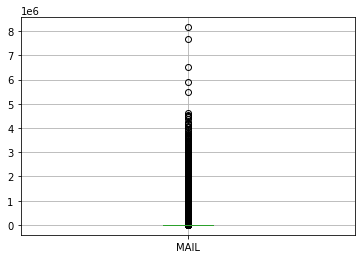

In [30]:
# Boxplot for 'MAIL'
df_cleaned.boxplot(column=['MAIL'])

In [31]:
# Checking top 5 outliers for 'MAIL' field
df_cleaned['MAIL'].nlargest(5)

508074     8163150.0
255906     7660663.0
758484     6530776.0
38591      5887892.0
1219627    5476382.0
Name: MAIL, dtype: float64

In [32]:
# Use indexing to check 5 rows with top 5 'MAIL' values
df_cleaned.iloc[[38591, 255906, 508074, 758484, 1219627]]

,PASSENGERS,FREIGHT,MAIL,DISTANCE,UNIQUE_CARRIER,UNIQUE_CARRIER_NAME,ORIGIN_AIRPORT_ID,ORIGIN,ORIGIN_CITY_NAME,ORIGIN_STATE_ABR,DEST_AIRPORT_ID,DEST,DEST_CITY_NAME,DEST_STATE_ABR,YEAR,QUARTER,MONTH,DISTANCE_GROUP
38591,0.0,2343790.0,5887892.0,1619.0,KAQ,Kalitta Air LLC,12892,LAX,"Los Angeles, CA",CA,13244,MEM,"Memphis, TN",TN,2016,4,12,4
255906,0.0,0.0,7660663.0,1619.0,KAQ,Kalitta Air LLC,12892,LAX,"Los Angeles, CA",CA,13244,MEM,"Memphis, TN",TN,2017,4,12,4
508074,0.0,0.0,8163150.0,1619.0,KAQ,Kalitta Air LLC,12892,LAX,"Los Angeles, CA",CA,13244,MEM,"Memphis, TN",TN,2018,4,12,4
758484,0.0,0.0,6530776.0,1619.0,KAQ,Kalitta Air LLC,12892,LAX,"Los Angeles, CA",CA,13244,MEM,"Memphis, TN",TN,2019,4,12,4
1219627,0.0,52101.0,5476382.0,1619.0,KAQ,Kalitta Air LLC,12892,LAX,"Los Angeles, CA",CA,13244,MEM,"Memphis, TN",TN,2021,4,12,4


<AxesSubplot:>

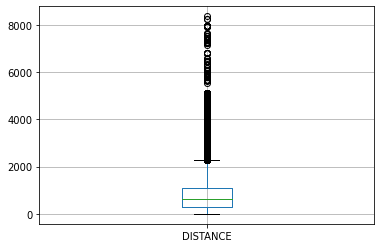

In [33]:
# Boxplot for 'DISTANCE'
df_cleaned.boxplot(column=['DISTANCE'])

## American Airlines Data

In [34]:
# Create a DataFrame with only American Airlines data
df_AA = df_cleaned.loc[df_cleaned['UNIQUE_CARRIER']=='AA'].copy()
df_AA.head()

,PASSENGERS,FREIGHT,MAIL,DISTANCE,UNIQUE_CARRIER,UNIQUE_CARRIER_NAME,ORIGIN_AIRPORT_ID,ORIGIN,ORIGIN_CITY_NAME,ORIGIN_STATE_ABR,DEST_AIRPORT_ID,DEST,DEST_CITY_NAME,DEST_STATE_ABR,YEAR,QUARTER,MONTH,DISTANCE_GROUP
9166,0.0,0.0,65.0,2213.0,AA,American Airlines Inc.,14107,PHX,"Phoenix, AZ",AZ,10529,BDL,"Hartford, CT",CT,2016,4,11,5
9299,0.0,0.0,307.0,2213.0,AA,American Airlines Inc.,14107,PHX,"Phoenix, AZ",AZ,10529,BDL,"Hartford, CT",CT,2016,4,10,5
9353,0.0,0.0,620.0,991.0,AA,American Airlines Inc.,14869,SLC,"Salt Lake City, UT",UT,13487,MSP,"Minneapolis, MN",MN,2016,4,10,2
10674,0.0,22.0,0.0,1012.0,AA,American Airlines Inc.,11278,DCA,"Washington, DC",VA,13871,OMA,"Omaha, NE",NE,2016,3,7,3
11426,0.0,60.0,0.0,949.0,AA,American Airlines Inc.,11278,DCA,"Washington, DC",VA,13198,MCI,"Kansas City, MO",MO,2016,3,8,2


In [35]:
# Order values by date (using YEAR and MONTH columns)
df_AA = df_AA.sort_values(by=['YEAR','MONTH'])

In [36]:
# Aggregate values by month/year while choosing relevant fields
df_AA.groupby(['YEAR', 'MONTH'])[['PASSENGERS', 'FREIGHT', 'MAIL', 'DISTANCE']].sum()

PASSENGERS     FREIGHT        MAIL   DISTANCE
YEAR MONTH                                               
2016 1       9046884.0  17169249.0  14036987.0  1610583.0
     2       8631620.0  18696096.0  10611029.0  1503524.0
     3      10232326.0  20928965.0   9908407.0  1361607.0
     4       9618310.0  19283386.0   9412838.0  1435686.0
     5      10288810.0  18658585.0  10153077.0  1410730.0
...                ...         ...         ...        ...
2026 3      11523168.0  15069900.0   2192280.0   979300.0
     4      11012075.0  11327800.0   2293756.0  1029056.0
     5      11903316.0  13309467.0   1603790.0  1046224.0
     6      11979881.0  12098653.0   1384125.0  1025853.0
     7      12262643.0  11558361.0   1463636.0  1016812.0

[127 rows x 4 columns]

In [37]:
# Create a DataFrame for field sums
df_AA_sum = df_AA.groupby(['YEAR', 'MONTH'])[['PASSENGERS', 'FREIGHT', 'MAIL', 'DISTANCE']].sum()

In [38]:
# # Create csv for AA data (for time series analysis in R)
# df_AA_sum.to_csv('T_T100D_MARKET_US_CARRIER_ONLY_DATA/AA_sum_2016-2026.csv', index=False)

### DFW Analysis

In [39]:
# Checking AA data with DFW as the origin
df_AA[df_AA['ORIGIN']=='DFW']

,PASSENGERS,FREIGHT,MAIL,DISTANCE,UNIQUE_CARRIER,UNIQUE_CARRIER_NAME,ORIGIN_AIRPORT_ID,ORIGIN,ORIGIN_CITY_NAME,ORIGIN_STATE_ABR,DEST_AIRPORT_ID,DEST,DEST_CITY_NAME,DEST_STATE_ABR,YEAR,QUARTER,MONTH,DISTANCE_GROUP
53276,3.0,0.0,0.0,821.0,AA,American Airlines Inc.,11298,DFW,"Dallas/Fort Worth, TX",TX,13485,MSN,"Madison, WI",WI,2016,1,1,2
89937,49.0,0.0,0.0,1662.0,AA,American Airlines Inc.,11298,DFW,"Dallas/Fort Worth, TX",TX,10559,BFI,"Seattle, WA",WA,2016,1,1,4
108942,121.0,0.0,0.0,247.0,AA,American Airlines Inc.,11298,DFW,"Dallas/Fort Worth, TX",TX,12191,HOU,"Houston, TX",TX,2016,1,1,1
125102,237.0,0.0,0.0,721.0,AA,American Airlines Inc.,11298,DFW,"Dallas/Fort Worth, TX",TX,11503,EGE,"Eagle, CO",CO,2016,1,1,2
178784,2595.0,4413.0,0.0,733.0,AA,American Airlines Inc.,11298,DFW,"Dallas/Fort Worth, TX",TX,14730,SDF,"Louisville, KY",KY,2016,1,1,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2591748,54906.0,19009.0,0.0,1389.0,AA,American Airlines Inc.,11298,DFW,"Dallas/Fort Worth, TX",TX,12953,LGA,"New York, NY",NY,2026,3,7,3
2591764,55788.0,61015.0,47326.0,802.0,AA,American Airlines Inc.,11298,DFW,"Dallas/Fort Worth, TX",TX,13930,ORD,"Chicago, IL",IL,2026,3,7,2
2591819,58185.0,351797.0,49711.0,1121.0,AA,American Airlines Inc.,11298,DFW,"Dallas/Fort Worth, TX",TX,13303,MIA,"Miami, FL",FL,2026,3,7,3
2591911,65164.0,29748.0,0.0,868.0,AA,American Airlines Inc.,11298,DFW,"Dallas/Fort Worth, TX",TX,14107,PHX,"Phoenix, AZ",AZ,2026,3,7,2


In [40]:
# Checking AA data with AA as the destination
df_AA[df_AA['DEST']=='DFW']

,PASSENGERS,FREIGHT,MAIL,DISTANCE,UNIQUE_CARRIER,UNIQUE_CARRIER_NAME,ORIGIN_AIRPORT_ID,ORIGIN,ORIGIN_CITY_NAME,ORIGIN_STATE_ABR,DEST_AIRPORT_ID,DEST,DEST_CITY_NAME,DEST_STATE_ABR,YEAR,QUARTER,MONTH,DISTANCE_GROUP
110176,126.0,0.0,0.0,247.0,AA,American Airlines Inc.,12191,HOU,"Houston, TX",TX,11298,DFW,"Dallas/Fort Worth, TX",TX,2016,1,1,1
125036,236.0,0.0,0.0,721.0,AA,American Airlines Inc.,11503,EGE,"Eagle, CO",CO,11298,DFW,"Dallas/Fort Worth, TX",TX,2016,1,1,2
176650,2451.0,0.0,0.0,282.0,AA,American Airlines Inc.,12896,LBB,"Lubbock, TX",TX,11298,DFW,"Dallas/Fort Worth, TX",TX,2016,1,1,1
181005,2752.0,1751.0,0.0,733.0,AA,American Airlines Inc.,14730,SDF,"Louisville, KY",KY,11298,DFW,"Dallas/Fort Worth, TX",TX,2016,1,1,2
183976,2990.0,0.0,0.0,328.0,AA,American Airlines Inc.,12278,ICT,"Wichita, KS",KS,11298,DFW,"Dallas/Fort Worth, TX",TX,2016,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2591796,57216.0,7258.0,0.0,1389.0,AA,American Airlines Inc.,12953,LGA,"New York, NY",NY,11298,DFW,"Dallas/Fort Worth, TX",TX,2026,3,7,3
2591827,58384.0,31302.0,202232.0,802.0,AA,American Airlines Inc.,13930,ORD,"Chicago, IL",IL,11298,DFW,"Dallas/Fort Worth, TX",TX,2026,3,7,2
2591850,60219.0,27585.0,0.0,868.0,AA,American Airlines Inc.,14107,PHX,"Phoenix, AZ",AZ,11298,DFW,"Dallas/Fort Worth, TX",TX,2026,3,7,2
2591882,62258.0,377396.0,31885.0,1121.0,AA,American Airlines Inc.,13303,MIA,"Miami, FL",FL,11298,DFW,"Dallas/Fort Worth, TX",TX,2026,3,7,3


In [41]:
# Selecting data with DFW as either origin or destination
df_AA_DFW = df_AA[(df_AA['ORIGIN']=='DFW') | (df_AA['DEST']=='DFW')]

In [42]:
# Order values by date (using YEAR and MONTH columns)
df_AA_DFW = df_AA_DFW.sort_values(by=['YEAR','MONTH'])

In [43]:
# Aggregate values by month/year while choosing relevant fields
df_AA_DFW.groupby(['YEAR', 'MONTH'])[['PASSENGERS', 'FREIGHT', 'MAIL', 'DISTANCE']].sum()

PASSENGERS    FREIGHT       MAIL  DISTANCE
YEAR MONTH                                            
2016 1       2974577.0  6664196.0  2972731.0  154349.0
     2       2823198.0  7287101.0  2106449.0  153356.0
     3       3218292.0  7248141.0  1766257.0  149464.0
     4       2984860.0  7233857.0  2165351.0  150277.0
     5       3177767.0  7227460.0  2450930.0  144232.0
...                ...        ...        ...       ...
2026 3       4023237.0  6972445.0   885942.0  222925.0
     4       3800380.0  4073772.0   935881.0  224248.0
     5       4088702.0  5474721.0   705302.0  245808.0
     6       4092627.0  4624333.0   636904.0  251473.0
     7       4275348.0  4158712.0   668027.0  250127.0

[127 rows x 4 columns]

In [44]:
# Create a DataFrame for field sums
df_AA_DFW_sum = df_AA_DFW.groupby(['YEAR', 'MONTH'])[['PASSENGERS', 'FREIGHT', 'MAIL', 'DISTANCE']].sum()

In [45]:
# # Create csv for AA data (for time series analysis in R)
# df_AA_DFW_sum.to_csv('T_T100D_MARKET_US_CARRIER_ONLY_DATA/AA_DFW_sum_2016-2026.csv', index=False)

##### Descriptive Statistics

In [46]:
df_AA_DFW_sum

PASSENGERS    FREIGHT       MAIL  DISTANCE
YEAR MONTH                                            
2016 1       2974577.0  6664196.0  2972731.0  154349.0
     2       2823198.0  7287101.0  2106449.0  153356.0
     3       3218292.0  7248141.0  1766257.0  149464.0
     4       2984860.0  7233857.0  2165351.0  150277.0
     5       3177767.0  7227460.0  2450930.0  144232.0
...                ...        ...        ...       ...
2026 3       4023237.0  6972445.0   885942.0  222925.0
     4       3800380.0  4073772.0   935881.0  224248.0
     5       4088702.0  5474721.0   705302.0  245808.0
     6       4092627.0  4624333.0   636904.0  251473.0
     7       4275348.0  4158712.0   668027.0  250127.0

[127 rows x 4 columns]

In [47]:
df_AA_DFW_sum.describe()

,PASSENGERS,FREIGHT,MAIL,DISTANCE
count,1.270000e+02,1.270000e+02,1.270000e+02,127.00000
mean,3.343917e+06,7.543734e+06,3.247569e+06,201730.15748
std,7.462456e+05,2.067763e+06,2.058352e+06,31499.92121
min,2.496430e+05,2.830595e+06,2.929570e+05,135499.00000
25%,3.144950e+06,5.992020e+06,8.700450e+05,176180.00000
50%,3.448345e+06,7.318815e+06,3.638976e+06,194176.00000
75%,3.824417e+06,9.189438e+06,4.924838e+06,229366.50000
max,4.592031e+06,1.241696e+07,7.373725e+06,255107.00000


##### Time Series Analysis

In [48]:
# Creating datetime object
df_AA_DFW_sum['DATE'] = pd.to_datetime([f'{y}-{m}-01' for y, m in df_AA_DFW_sum.index])

In [49]:
# Viewing new date column
df_AA_DFW_sum.head()

PASSENGERS    FREIGHT       MAIL  DISTANCE       DATE
YEAR MONTH                                                       
2016 1       2974577.0  6664196.0  2972731.0  154349.0 2016-01-01
     2       2823198.0  7287101.0  2106449.0  153356.0 2016-02-01
     3       3218292.0  7248141.0  1766257.0  149464.0 2016-03-01
     4       2984860.0  7233857.0  2165351.0  150277.0 2016-04-01
     5       3177767.0  7227460.0  2450930.0  144232.0 2016-05-01

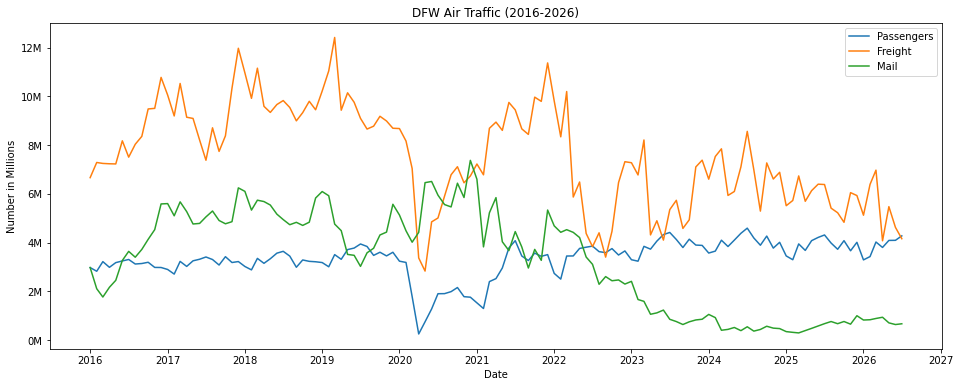

In [50]:
# 3 time series plots in one figure
plt.figure(figsize=(16,6))
plt.plot(df_AA_DFW_sum.DATE, df_AA_DFW_sum.PASSENGERS, label='Passengers')
plt.plot(df_AA_DFW_sum.DATE, df_AA_DFW_sum.FREIGHT, label='Freight')
plt.plot(df_AA_DFW_sum.DATE, df_AA_DFW_sum.MAIL, label='Mail')

# Define formatter function
def format_func(value, tick_number):
    return f'{int(value/1000000)}M'

plt.gca().xaxis.set_major_locator(mdates.YearLocator())
plt.gca().yaxis.set_major_formatter(ticker.FuncFormatter(format_func))
plt.xlabel('Date')
plt.ylabel('Number in Millions')
plt.title('DFW Air Traffic (2016-2026)')
plt.legend()
plt.show()

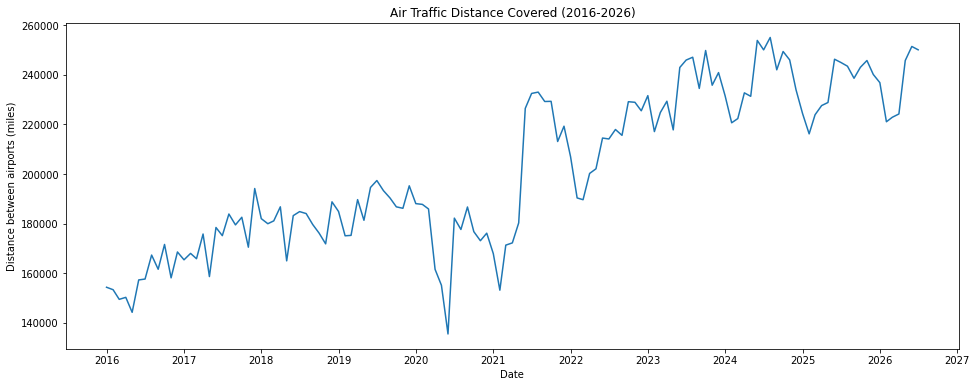

In [51]:
# Plot 'DISTANCE' time series plot separately
plt.figure(figsize=(16,6))
plt.plot(df_AA_DFW_sum.DATE, df_AA_DFW_sum.DISTANCE, label='Distance')

plt.gca().xaxis.set_major_locator(mdates.YearLocator())
plt.xlabel('Date')
plt.ylabel('Distance between airports (miles)')
plt.title('Air Traffic Distance Covered (2016-2026)')
plt.show()

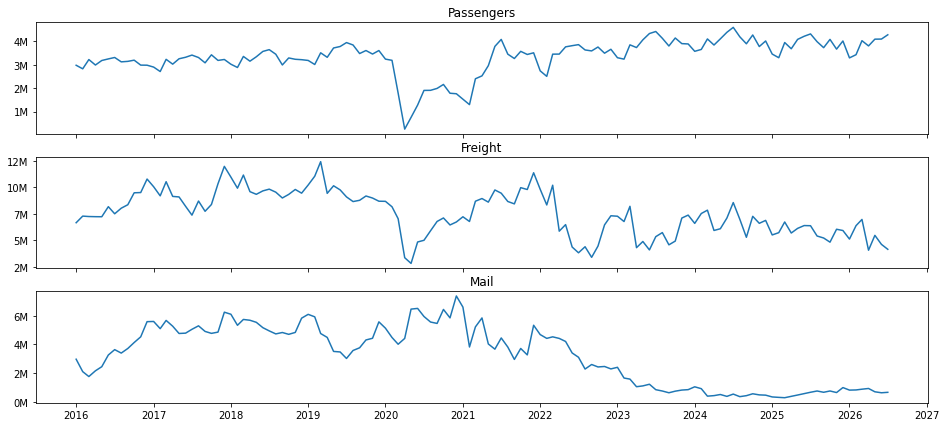

In [52]:
# Subplots
fig, axs = plt.subplots(3,1, figsize=(16,7), sharex=True)
axs[0].plot(df_AA_DFW_sum.DATE, df_AA_DFW_sum.PASSENGERS) ; axs[0].set_title('Passengers')
axs[1].plot(df_AA_DFW_sum.DATE, df_AA_DFW_sum.FREIGHT) ; axs[1].set_title('Freight')
axs[2].plot(df_AA_DFW_sum.DATE, df_AA_DFW_sum.MAIL)  ; axs[2].set_title('Mail')

plt.gca().xaxis.set_major_locator(mdates.YearLocator())
for ax in axs.flat:
    ax.yaxis.set_major_formatter(ticker.FuncFormatter(format_func))
plt.show()

##### Decomposition Plot

In [55]:
# Reindex based on time column
df_AA_DFW_sum = df_AA_DFW_sum.set_index('DATE')

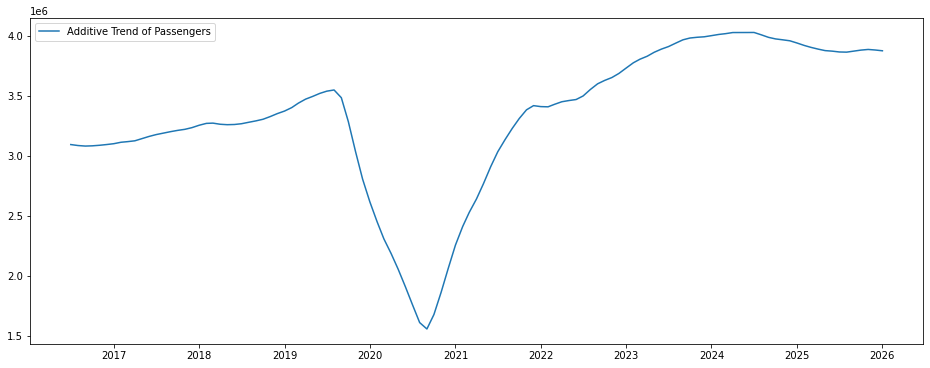

In [60]:
# Applying Additive Decomposition to 'PASSENGERS' Field
result_add = seasonal_decompose(df_AA_DFW_sum['PASSENGERS'], model='additive')

plt.figure(figsize=(16, 6))
plt.plot(result_add.trend, label='Additive Trend of Passengers')
plt.legend()
plt.show()

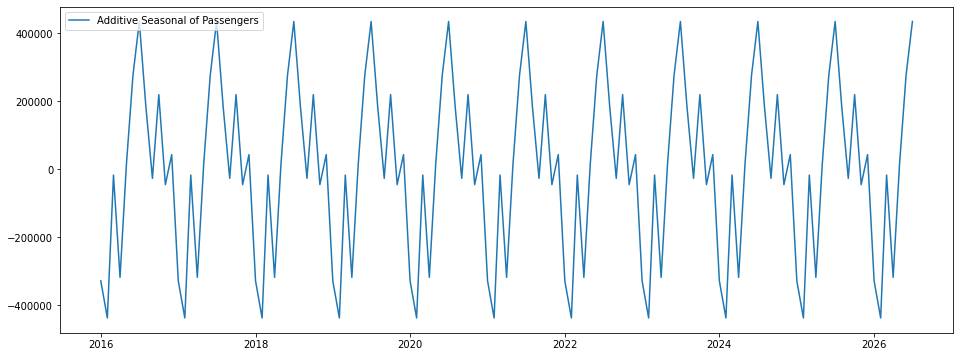

In [61]:
# Plotting Seasonal Component
plt.figure(figsize=(16,6))
plt.plot(result_add.seasonal, label='Additive Seasonal of Passengers')
plt.legend()
plt.show()

##### Forecasting

For forecasting, I will choose a time period after the 2020 pandemic when the data seems to stabilize. Since ARIMA models typically need 3-5 years of data or around 50 data points, I will choose data starting from 2021-07-01 to 2026-07-01.

In [71]:
df_period = df_AA_DFW_sum.loc['2021-07-01':'2026-07-01']

In [74]:
# Checking if time series is stationary
ts = df_AA_DFW_sum['PASSENGERS']
result = adfuller(ts)
print(f'ADF Statistic: {result[1]}')
print(f'p-value: {result[1]}')

if result[1] > 0.05:
    print('Series is non stationary; differencing is needed.')
else:
    print('Series is stationary; no differencing needed.')

ADF Statistic: 0.3293805727857546
p-value: 0.3293805727857546
Series is non stationary; differencing is needed.


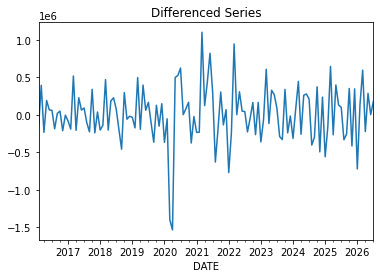

ADF Statistic (differenced): -3.3605991168140426
p-value (differenced: 0.012377659043180955)


In [75]:
# Performing differencing
ts_diff = ts.diff().dropna()

ts_diff.plot(title='Differenced Series')
plt.show()

result_diff = adfuller(ts_diff)
print(f'ADF Statistic (differenced): {result_diff[0]}')
print(f'p-value (differenced: {result_diff[1]})')

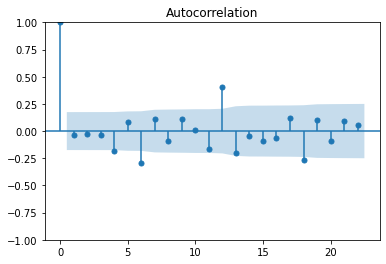

/home/alex_nanez/.local/lib/python3.8/site-packages/statsmodels/graphics/tsaplots.py:348: FutureWarning: The default method 'yw' can produce PACF values outside of the [-1,1] interval. After 0.13, the default will change tounadjusted Yule-Walker ('ywm'). You can use this method now by setting method='ywm'.
  warnings.warn(


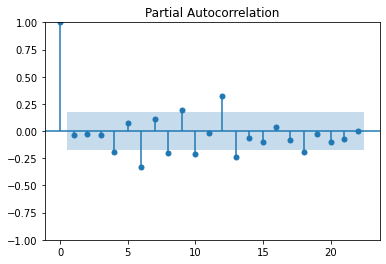

In [76]:
# Autocorrelation Function (ACF) and Partial Autocorrelation Function (PACF) Plotting
plot_acf(ts_diff)
plt.show()

plot_pacf(ts_diff)
plt.show()

In [78]:
import warnings
warnings.filterwarnings('ignore')

In [79]:
# ARIMA Model Selection
p = range(0, 4)
d = range(0, 3)
q = range(0, 4)
pdq = list(itertools.product(p, d, q))

best_aic = np.inf
best_order = None
best_model = None

for order in pdq:
    try:
        model = ARIMA(ts, order=order)
        results = model.fit()
        if results.aic < best_aic:
            best_aic = results.aic
            best_order = order
            best_model = results
    except:
        continue

print(f'Best ARIMA order: {best_order} with AIC: {best_aic}')

Best ARIMA order: (3, 2, 3) with AIC: 3567.642269207361


In [82]:
# Model Fitting and Forecasting
final_model = ARIMA(ts, order=best_order)
results = final_model.fit()

forecast_values = results.forecast(steps=10)

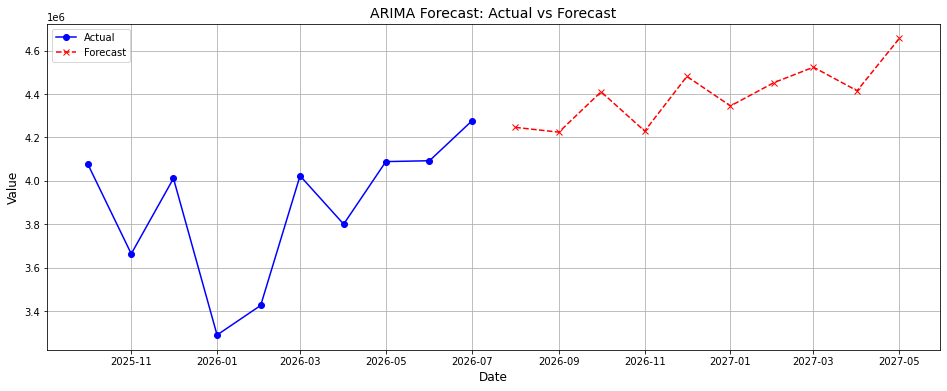

In [84]:
# Model Evaluation

# Plot last 10 values of original data along with forecasted values
plt.figure(figsize=(16,6))

plt.plot(ts[-10:].index, ts[-10:], label='Actual', color='blue', linestyle='-', marker='o')
plt.plot(forecast_values.index, forecast_values, label='Forecast', color='red', linestyle='--', marker='x')

plt.title('ARIMA Forecast: Actual vs Forecast', fontsize=14)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Value', fontsize=12)
plt.legend()
plt.grid(True)
plt.show()